# Classical AI: Uninformed Search

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and the previous notebook in this track. It also works as exam or interview revision on BFS, DFS and friends.
>
> **What you will learn**
> - The vocabulary of search: **node**, **frontier**, **expand**, **explored / reached set**, **tree search vs graph search**
> - Six **uninformed** (blind) strategies, written from scratch: **breadth-first (BFS)**, **depth-first (DFS)**, **depth-limited (DLS)**, **iterative deepening (IDS)**, **uniform-cost (UCS)** and **bidirectional BFS**
> - How to measure them: nodes expanded, frontier size, path length and path cost, with **asserts** against NetworkX
> - The textbook comparison table (complete? optimal? time? space?) in AIMA's $b, d, m, C^*, \epsilon$ notation, and *why* each entry is true
> - Solving the **water jug** and **missionaries & cannibals** puzzles from notebook 01
>
> **Prerequisites:** [`01_types_of_ai_and_intelligent_agents.ipynb`](01_types_of_ai_and_intelligent_agents.ipynb) (problem formulation, state spaces) and [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) (functions, classes, dicts).
>
> **Time needed:** about 2-3 hours.
>
> **Runs on:** CPU, no API key, about a minute to run everything.
>
> **Optional track:** part of the **university-level fundamentals track**. We recommend it for BS/MS AI students and for interview prep.

## Explained simply

Searching is how a computer finds a way from where it is to where it wants to be, when it has **no clue** which direction is better. It keeps a to-do list of places it knows about but has not checked yet, and the only real question is *which one to check next*. **Breadth-first search (BFS)** checks every place 1 step away, then every place 2 steps away, and so on. It is like searching for a lost child by checking every nearby street before going further. **Depth-first search (DFS)** follows one path as far as it goes and only then backs up, like exploring a cave by always taking the first tunnel. **Uniform-cost search** always continues the cheapest trip found so far, like a delivery driver who always extends the shortest route on the list. These "blind" methods are the foundation that the smarter methods in the next notebook build on.

**A tiny example.** From your home you can walk to the shop or to the park (1 street each). From the shop you can reach the school, and from the park you can reach your friend's house (1 more street each). BFS first checks the shop and the park (1 street away), then the school and your friend's house (2 streets away), and finds your friend after 2 streets, the shortest possible. DFS might go home → shop → school and keep going in that direction, and only later come back to try the park.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| BFS | check everything 1 step away, then 2 steps, then 3 ... | "people you may know" (friends of friends), web crawlers |
| DFS | go as deep as possible, then back up and try the next branch | solving a maze by always taking the first turning; generating mazes |
| Uniform-cost search (Dijkstra) | always extend the cheapest route found so far | internet routing, shortest-route apps |

## Contents

1. Search vocabulary: nodes, frontier, expansion
2. Tree search vs graph search
3. Our two test worlds: a road map and a maze
4. Breadth-first search (BFS)
5. Depth-first search (DFS)
6. Depth-limited search (DLS) and iterative deepening (IDS)
7. Uniform-cost search (UCS)
8. Bidirectional BFS
9. The race: all six on the maze, plus the 8-puzzle
10. The comparison table: complete? optimal? time? space?
11. Solving the water jug and missionaries & cannibals puzzles
12. How this connects to modern AI
13. Recap, practice problems, further reading

In [1]:
import math                         # sqrt, inf
import random                       # seeded randomness
import sys                          # recursion limit for depth-limited search
import time                         # timing
import heapq                        # priority queue for uniform-cost search
import itertools                    # a tie-breaking counter
from collections import deque       # FIFO queue for BFS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

SEED = 7
random.seed(SEED); np.random.seed(SEED)
sys.setrecursionlimit(10_000)       # DLS recurses once per level of depth
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100

## 1. Search vocabulary

> 💬 **In plain English:** search keeps a to-do list of places to visit; the order in which you take places off that list is the whole algorithm.

**Intuition.** You are lost in a building and looking for the exit. You keep a list of **doors you know about but have not opened yet**. You pick one door, walk through, note any new doors, and repeat. *Which door you pick next* is the whole difference between the search algorithms in this notebook.

| Term | Meaning |
|---|---|
| **Node** | a data structure in the search tree: a **state**, a pointer to its **parent** node, the **action** that produced it, the **path cost** $g(n)$ from the start, and its **depth** |
| **Expand** a node | generate all its children: apply every action in `ACTIONS(state)` |
| **Generate** | create a child node (each expansion generates up to $b$ nodes) |
| **Frontier** (or *open list*, *fringe*) | the generated nodes that are waiting to be expanded: the doors not yet opened |
| **Explored set** (*closed list*) / **reached set** | the states already expanded (or already generated), so we do not do them again |
| **Uninformed** (blind) search | a strategy that knows nothing about the problem except its definition: it cannot tell whether one non-goal state is "closer" to the goal than another |

**The only difference between BFS, DFS and UCS is the frontier's data structure:**

| Strategy | Frontier | Takes out next |
|---|---|---|
| BFS | FIFO **queue** | the *oldest* (shallowest) node |
| DFS | LIFO **stack** | the *newest* (deepest) node |
| UCS | **priority queue** keyed on $g(n)$ | the *cheapest* node |

We start with the `Problem` class from notebook 01 and add a `Node` class.

In [2]:
class Problem:
    # A search problem; subclasses override actions, result, and optionally is_goal / action_cost.
    def __init__(self, initial, goal=None):
        self.initial, self.goal = initial, goal
    def actions(self, state):             raise NotImplementedError
    def result(self, state, action):      raise NotImplementedError
    def is_goal(self, state):             return state == self.goal
    def action_cost(self, s, a, s2):      return 1

class Node:
    # A node in the search tree.
    __slots__ = ("state", "parent", "action", "path_cost", "depth")
    def __init__(self, state, parent=None, action=None, path_cost=0):
        self.state = state                        # the state this node represents
        self.parent = parent                      # the node we came from
        self.action = action                      # the action that got us here
        self.path_cost = path_cost                # g(n): cost from the start
        self.depth = 0 if parent is None else parent.depth + 1
    def __repr__(self):
        return f"<Node {self.state} g={self.path_cost}>"

def expand(problem, node):
    # Generate the children of `node`, one per applicable action.
    s = node.state
    for action in problem.actions(s):
        s2 = problem.result(s, action)
        cost = node.path_cost + problem.action_cost(s, action, s2)
        yield Node(s2, node, action, cost)

def path_states(node):
    # The list of states from the root to `node`.
    states = []
    while node is not None:
        states.append(node.state); node = node.parent
    return states[::-1]

def path_actions(node):
    # The list of actions from the root to `node` (the solution).
    actions = []
    while node is not None and node.parent is not None:
        actions.append(node.action); node = node.parent
    return actions[::-1]

class Stats:
    # What we measure for every search run.
    def __init__(self, name):
        self.name = name
        self.expanded = []          # states in the order they were expanded
        self.generated = 0          # number of nodes created
        self.max_frontier = 0       # largest frontier size seen (a memory measure)
        self.frontier_end = []      # states left in the frontier when the search stopped
    def note_frontier(self, size):
        self.max_frontier = max(self.max_frontier, size)

## 2. Tree search vs graph search

> 💬 **In plain English:** if you don't remember where you've already been, you can walk in circles forever.

In AIMA's words, the two general algorithms are:

```
TREE-SEARCH(problem):                          GRAPH-SEARCH(problem):
  frontier <- {root}                             frontier <- {root};  explored <- {}
  loop:                                          loop:
    if frontier empty: return failure              if frontier empty: return failure
    node <- REMOVE(frontier)                       node <- REMOVE(frontier)
    if GOAL(node.state): return node               if GOAL(node.state): return node
                                                   if node.state in explored: skip it
                                                   add node.state to explored
    add EXPAND(node) to frontier                   add children whose state is not explored
```

The only change is the **explored set**: graph search remembers what it has already expanded and never expands it twice. As notebook 01 showed, a tree search on a graph with cycles builds a tree that can be exponentially large or even infinite.

Below, one function does both, with either a FIFO queue (breadth-first) or a LIFO stack (depth-first). We run it on an open 5 × 5 grid, from the top-left corner to the bottom-right corner. Tree search gets an expansion budget of 20,000 so that it cannot run forever.

In [3]:
class GridProblem(Problem):
    # Move Up/Down/Left/Right on a grid; grid[r][c] == 1 is a wall. Optional per-square entry costs.
    MOVES = {"Up": (-1, 0), "Down": (1, 0), "Left": (0, -1), "Right": (0, 1)}
    def __init__(self, grid, start, goal, costs=None):
        super().__init__(start, goal)
        self.grid = np.asarray(grid)
        self.costs = costs                              # None -> every step costs 1
    def actions(self, s):
        H, W = self.grid.shape
        acts = []
        for a, (dr, dc) in self.MOVES.items():
            r, c = s[0] + dr, s[1] + dc
            if 0 <= r < H and 0 <= c < W and self.grid[r, c] == 0:
                acts.append(a)
        return acts
    def result(self, s, a):
        dr, dc = self.MOVES[a]
        return (s[0] + dr, s[1] + dc)
    def action_cost(self, s, a, s2):
        return 1 if self.costs is None else self.costs[s2]   # pay the cost of the square you enter

def generic_search(problem, kind="FIFO", graph_search=True, budget=20_000):
    # TREE-SEARCH (graph_search=False) or GRAPH-SEARCH (graph_search=True); goal test when a node is removed.
    stats = Stats(f"{kind} {'graph' if graph_search else 'tree'} search")
    frontier = deque([Node(problem.initial)])
    explored = set()
    while frontier:
        stats.note_frontier(len(frontier))
        node = frontier.popleft() if kind == "FIFO" else frontier.pop()   # the ONLY difference BFS vs DFS
        if problem.is_goal(node.state):
            return node, stats
        if graph_search:
            if node.state in explored:          # already expanded via another path
                continue
            explored.add(node.state)
        if len(stats.expanded) >= budget:       # give up: we would loop forever
            return "gave up", stats
        stats.expanded.append(node.state)
        for child in expand(problem, node):
            if not graph_search or child.state not in explored:
                frontier.append(child); stats.generated += 1
    return None, stats

open_grid = GridProblem(np.zeros((5, 5), dtype=int), (0, 0), (4, 4))
rows = []
for kind in ("FIFO", "LIFO"):
    for graph in (False, True):
        result, st = generic_search(open_grid, kind, graph)
        found = isinstance(result, Node)
        rows.append({"search": st.name, "found goal?": found if found else result,
                     "path length": len(path_actions(result)) if found else None,
                     "nodes expanded": len(st.expanded), "max frontier": st.max_frontier})
print(pd.DataFrame(rows).to_string(index=False))

           search found goal?  path length  nodes expanded  max frontier
 FIFO tree search        True          8.0            4490         10967
FIFO graph search        True          8.0              24             9
 LIFO tree search     gave up          NaN           20000         30002
LIFO graph search        True         24.0              24            17


**What just happened?**
- **BFS as tree search** still finds the shortest path (8 moves), but it expands about 4,500 nodes on a grid with only 25 squares. It re-expands the same squares through every different path, and its frontier grows to more than 10,000 nodes.
- **BFS as graph search** expands each square at most once.
- **DFS as tree search** never finds the goal. It walks right along the top row, then bounces forever between the last two squares, because "go back" is always a legal move and nothing remembers that it was just there. We stopped it at the budget.
- **DFS as graph search** finds *a* path, but a long and silly one, because it always dives into the newest branch.

> ⚠️ **Common mistake:** the explored set must contain **states**, not nodes. Two nodes with the same state are the same place reached by different paths, and expanding both is wasted work.

> 🎓 **Exam / interview tip:** "graph search" is about *what the algorithm remembers*, not about the problem being a graph. Every problem has a state-space graph; tree search simply ignores the fact that paths can meet again.

## 3. Our two test worlds

> 💬 **In plain English:** a road map and a maze, so every algorithm can be tried on the same problems.

**World 1: the road map from notebook 01.** 12 towns; find a route from **Ashford** to **Lakeside**. Roads have different lengths, so "fewest roads" and "fewest km" are different questions.

**World 2: a maze.** A 21 × 21 grid made by a classic random maze generator (a randomised depth-first carving), with 25 extra holes knocked in the walls so that there are **loops** (several routes). Some squares are **mud** (brown): entering a mud square costs 5 instead of 1. The start is top-left, the goal is bottom-right.

In [4]:
CITY_XY = {
    "Ashford": (10, 80), "Brookvale": (30, 92), "Cedar Falls": (22, 58), "Dunmore": (48, 78),
    "Elmstead": (42, 50), "Fairhaven": (70, 88), "Glenwood": (68, 56), "Harborview": (92, 72),
    "Ironbridge": (15, 28), "Juniper": (45, 22), "Kingsport": (78, 32), "Lakeside": (96, 12),
}
ROADS = [
    ("Ashford", "Brookvale", 26), ("Ashford", "Cedar Falls", 28), ("Brookvale", "Dunmore", 25),
    ("Cedar Falls", "Dunmore", 40), ("Cedar Falls", "Elmstead", 24), ("Cedar Falls", "Ironbridge", 34),
    ("Dunmore", "Fairhaven", 27), ("Dunmore", "Elmstead", 33), ("Elmstead", "Glenwood", 31),
    ("Elmstead", "Juniper", 30), ("Fairhaven", "Harborview", 30), ("Fairhaven", "Glenwood", 36),
    ("Glenwood", "Harborview", 32), ("Glenwood", "Kingsport", 29), ("Ironbridge", "Juniper", 33),
    ("Juniper", "Kingsport", 38), ("Kingsport", "Lakeside", 29), ("Harborview", "Lakeside", 64),
]
road_map = {c: {} for c in CITY_XY}
for a, b, km in ROADS:
    road_map[a][b] = km; road_map[b][a] = km

class RouteProblem(Problem):
    def __init__(self, initial, goal, graph):
        super().__init__(initial, goal); self.graph = graph
    def actions(self, city):           return sorted(self.graph[city])   # alphabetical, so traces are reproducible
    def result(self, city, action):    return action
    def action_cost(self, c, a, c2):   return self.graph[c][c2]

route = RouteProblem("Ashford", "Lakeside", road_map)
G_map = nx.Graph(); G_map.add_weighted_edges_from(ROADS)          # NetworkX copy, used only for checking
print("fewest roads (networkx):", nx.shortest_path_length(G_map, "Ashford", "Lakeside"))
print("fewest km    (networkx):", nx.shortest_path_length(G_map, "Ashford", "Lakeside", weight="weight"))

fewest roads (networkx): 5
fewest km    (networkx): 141


maze: (21, 21), free squares: 224, mud squares: 33
fewest steps (networkx): 48 | cheapest cost with mud (networkx): 68


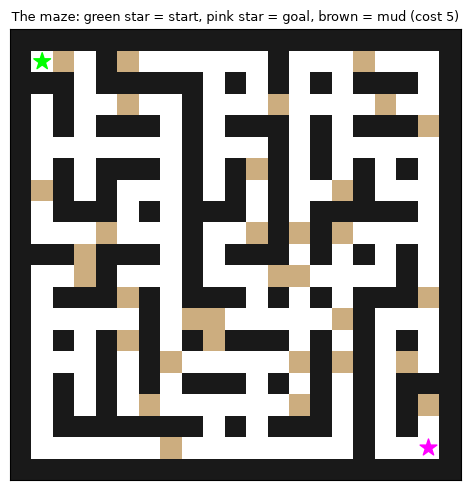

In [5]:
def make_maze(h_cells, w_cells, extra_openings, mud_fraction, seed):
    # Random maze: carve passages with randomised DFS, then knock out extra walls to make loops.
    rng = random.Random(seed)
    H, W = 2 * h_cells + 1, 2 * w_cells + 1
    grid = np.ones((H, W), dtype=int)                       # start with all walls
    stack = [(1, 1)]; grid[1, 1] = 0
    while stack:                                            # the carving itself is a DFS!
        r, c = stack[-1]
        options = [(dr, dc) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
                   if 0 < r + dr < H and 0 < c + dc < W and grid[r + dr, c + dc] == 1]
        if options:
            dr, dc = rng.choice(options)
            grid[r + dr // 2, c + dc // 2] = 0              # remove the wall between
            grid[r + dr, c + dc] = 0
            stack.append((r + dr, c + dc))
        else:
            stack.pop()
    inner_walls = [(r, c) for r in range(1, H - 1) for c in range(1, W - 1)
                   if grid[r, c] == 1 and (r % 2) != (c % 2)]   # walls between two cells
    for r, c in rng.sample(inner_walls, extra_openings):
        grid[r, c] = 0                                       # open a loop
    costs = np.ones((H, W), dtype=int)
    free = [(r, c) for r in range(H) for c in range(W) if grid[r, c] == 0]
    for cell in rng.sample(free, int(mud_fraction * len(free))):
        costs[cell] = 5                                      # mud
    start, goal = (1, 1), (H - 2, W - 2)
    costs[start] = costs[goal] = 1
    return grid, costs, start, goal

GRID, COSTS, START, GOAL = make_maze(10, 10, extra_openings=25, mud_fraction=0.15, seed=SEED)
maze = GridProblem(GRID, START, GOAL)                 # unit costs (for BFS, DFS, IDS, bidirectional)
muddy_maze = GridProblem(GRID, START, GOAL, COSTS)    # mud costs 5 (for UCS)

# NetworkX copies for checking our answers.
G_maze = nx.DiGraph()
for r in range(GRID.shape[0]):
    for c in range(GRID.shape[1]):
        if GRID[r, c] == 0:
            for a in maze.actions((r, c)):
                s2 = maze.result((r, c), a)
                G_maze.add_edge((r, c), s2, weight=int(COSTS[s2]))
D_STEPS = nx.shortest_path_length(G_maze, START, GOAL)                    # fewest steps
C_STAR = nx.shortest_path_length(G_maze, START, GOAL, weight="weight")    # cheapest cost with mud
print(f"maze: {GRID.shape}, free squares: {G_maze.number_of_nodes()}, mud squares: {(COSTS == 5).sum()}")
print("fewest steps (networkx):", D_STEPS, "| cheapest cost with mud (networkx):", C_STAR)

from matplotlib.colors import LogNorm

def draw_maze(ax, stats=None, path=None, title="", show_mud=True, second=None, by_count=False):
    # Walls black, mud brown; expanded squares coloured by expansion order (or by how many times
    # they were expanded, if by_count=True); frontier as x; path as a line.
    img = np.ones(GRID.shape + (3,))
    img[GRID == 1] = (0.1, 0.1, 0.1)
    if show_mud:
        img[(COSTS == 5) & (GRID == 0)] = (0.80, 0.68, 0.50)
    ax.imshow(img)
    if stats is not None and stats.expanded:
        order = np.full(GRID.shape, np.nan)
        if by_count:
            for s in stats.expanded:
                order[s] = 1 if np.isnan(order[s]) else order[s] + 1   # count expansions per square
            ax.imshow(np.ma.masked_invalid(order), cmap="viridis", alpha=0.75, norm=LogNorm())
        else:
            for i, s in enumerate(stats.expanded):
                if np.isnan(order[s]): order[s] = i             # first time this square was expanded
            ax.imshow(np.ma.masked_invalid(order), cmap="viridis", alpha=0.75)
        if stats.frontier_end:
            fr, fc = zip(*set(stats.frontier_end))
            ax.scatter(fc, fr, marker="x", s=18, color="red", label="frontier at the end")
    if second is not None and second.expanded:                 # backward half of bidirectional search
        rr, cc = zip(*second.expanded)
        ax.scatter(cc, rr, marker="s", s=22, color="orange", alpha=0.8, label="backward search")
    if path:
        pr, pc = zip(*path)
        ax.plot(pc, pr, color="white", lw=3); ax.plot(pc, pr, color="crimson", lw=1.5)
    ax.scatter([START[1], GOAL[1]], [START[0], GOAL[0]], marker="*", s=160, color=["lime", "magenta"], zorder=4)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

def legend_if_any(ax):
    # Only draw a legend when something in the plot has a label (avoids a matplotlib warning).
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="lower left", fontsize=7)

fig, ax = plt.subplots(figsize=(5, 5))
draw_maze(ax, title="The maze: green star = start, pink star = goal, brown = mud (cost 5)")
plt.tight_layout(); plt.show()

**What just happened?** We built the maze and NetworkX copies of both worlds. NetworkX's `shortest_path_length` is a trusted library answer. Every algorithm we write below will be checked against it with `assert`.

Fun fact: the maze generator itself is a **depth-first search**. It keeps a stack, carves forward into an unvisited cell, and backtracks at dead ends. DFS makes long, winding corridors, which is why mazes made this way look the way they do.

## 4. Breadth-first search (BFS)

> 💬 **In plain English:** check everything 1 step away, then everything 2 steps away, and so on.

**Intuition.** Drop a stone in a pond: the ripple reaches everything 1 step away, then everything 2 steps away, and so on. BFS expands all nodes at depth 1, then all at depth 2, and so on. *Analogy:* asking all your friends, then all friends-of-friends, then friends-of-friends-of-friends.

**Definition.** **Breadth-first search** expands the **shallowest** unexpanded node first, using a **FIFO queue** as the frontier.

**Early goal test.** BFS can check whether a child is a goal *when it is generated*, instead of waiting until it is removed from the queue. Every node generated at depth $d$ is found before any node at depth $d+1$, so the first goal generated is a shallowest goal. This saves expanding a whole layer.

**Worked example by hand** (towns in alphabetical order, start Ashford):

| Step | Expand | Children generated | Frontier after (FIFO, left = next) |
|---|---|---|---|
| 1 | Ashford | Brookvale, Cedar Falls | Brookvale, Cedar Falls |
| 2 | Brookvale | Dunmore | Cedar Falls, Dunmore |
| 3 | Cedar Falls | Elmstead, Ironbridge (Dunmore already reached) | Dunmore, Elmstead, Ironbridge |
| 4 | Dunmore | Fairhaven | Elmstead, Ironbridge, Fairhaven |
| ... | ... | ... | ... |

The code below prints the full trace so you can check your own.

In [6]:
def breadth_first_search(problem, trace=None):
    # BFS graph search with the early goal test. Returns (goal node or None, Stats).
    stats = Stats("BFS")
    node = Node(problem.initial)
    if problem.is_goal(node.state):
        return node, stats
    frontier = deque([node])                    # FIFO queue
    reached = {problem.initial}                 # states already generated
    while frontier:
        stats.note_frontier(len(frontier))
        node = frontier.popleft()               # shallowest node
        stats.expanded.append(node.state)
        new = []
        for child in expand(problem, node):
            stats.generated += 1
            s = child.state
            if problem.is_goal(s):              # early goal test
                stats.frontier_end = [n.state for n in frontier]
                if trace is not None:
                    trace.append((node.state, new + [s], "GOAL FOUND"))
                return child, stats
            if s not in reached:                # graph search: skip states already reached
                reached.add(s)
                frontier.append(child); new.append(s)
        if trace is not None:
            trace.append((node.state, new, ", ".join(n.state for n in frontier)))
    return None, stats

trace = []
bfs_node, bfs_stats = breadth_first_search(route, trace)
print(pd.DataFrame(trace, columns=["expand", "new children", "frontier after"]).to_string())
print("\nBFS route:", " -> ".join(path_states(bfs_node)))
print("roads used:", bfs_node.depth, "| km:", bfs_node.path_cost, "| nodes expanded:", len(bfs_stats.expanded))
assert bfs_node.depth == nx.shortest_path_length(G_map, "Ashford", "Lakeside")   # fewest roads: optimal

        expand              new children                            frontier after
0      Ashford  [Brookvale, Cedar Falls]                    Brookvale, Cedar Falls
1    Brookvale                 [Dunmore]                      Cedar Falls, Dunmore
2  Cedar Falls    [Elmstead, Ironbridge]             Dunmore, Elmstead, Ironbridge
3      Dunmore               [Fairhaven]           Elmstead, Ironbridge, Fairhaven
4     Elmstead       [Glenwood, Juniper]  Ironbridge, Fairhaven, Glenwood, Juniper
5   Ironbridge                        []              Fairhaven, Glenwood, Juniper
6    Fairhaven              [Harborview]             Glenwood, Juniper, Harborview
7     Glenwood               [Kingsport]            Juniper, Harborview, Kingsport
8      Juniper                        []                     Harborview, Kingsport
9   Harborview                [Lakeside]                                GOAL FOUND

BFS route: Ashford -> Brookvale -> Dunmore -> Fairhaven -> Harborview -> Lakeside
road

**What just happened?** BFS found a route with the **fewest roads** (5), which is what it guarantees. The assert checks that against NetworkX. But the route goes via Harborview and costs **172 km**. The cheapest route (141 km, Section 7) also uses 5 roads, but BFS cannot tell them apart: it counts steps, not kilometres.

Now the maze. The colours show *when* each square was expanded (dark purple = early, yellow = late). Red crosses mark the frontier at the moment BFS stopped.

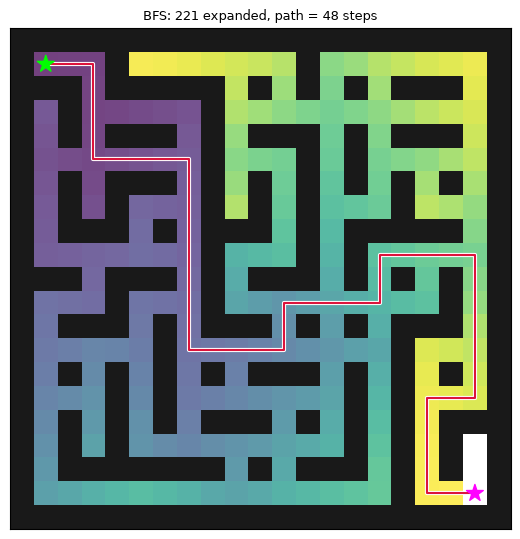

steps: 48 (networkx: 48 ) | max frontier: 12


In [7]:
bfs_m, bfs_m_stats = breadth_first_search(maze)
bfs_path = path_states(bfs_m)
assert bfs_m.depth == D_STEPS                   # BFS is optimal in number of steps
fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_maze(ax, bfs_m_stats, bfs_path, f"BFS: {len(bfs_m_stats.expanded)} expanded, path = {bfs_m.depth} steps", show_mud=False)
legend_if_any(ax); plt.tight_layout(); plt.show()
print("steps:", bfs_m.depth, "(networkx:", D_STEPS, ") | max frontier:", bfs_m_stats.max_frontier)

**What just happened?** The colour bands spread out from the start like a ripple, following the corridors. BFS expanded most of the maze before reaching the far corner, because the goal is far from the start. The frontier stays small here because a maze is narrow: few squares share the same distance.

**Complexity.** Let $b$ = branching factor and $d$ = depth of the shallowest goal. In the worst case BFS generates $b + b^2 + \dots + b^d = O(b^d)$ nodes (with the early goal test). Every generated node stays in memory (frontier or reached set), so **time and space are both $O(b^d)$**. Memory is the real problem. AIMA's example: with $b = 10$, a million nodes per second and 1 KB per node, a search to depth 10 generates about $10^{10}$ nodes. That takes about 3 hours, which is bearable, but needs about 10 terabytes of memory, which is not.

- **Complete?** Yes, if $b$ is finite (it eventually reaches every depth).
- **Optimal?** Yes **if all actions cost the same**. Otherwise no, as the 172 km route showed.

## 5. Depth-first search (DFS)

> 💬 **In plain English:** follow one path as far as it goes, and back up only at a dead end.

**Intuition.** Explore a cave by always taking the first unexplored tunnel and going as deep as possible. Only when you hit a dead end do you back up to the last fork. *Analogy:* reading a choose-your-own-adventure book by always following the first choice until the story ends, then flipping back.

**Definition.** **Depth-first search** expands the **deepest** unexpanded node first, using a **LIFO stack** as the frontier.

We implement the graph-search version (with an explored set), so it cannot loop. We push children in reverse order, so the *first* action is tried first.

DFS route: Ashford -> Brookvale -> Dunmore -> Cedar Falls -> Elmstead -> Glenwood -> Fairhaven -> Harborview -> Lakeside
roads: 8 | km: 276 | expanded: 8


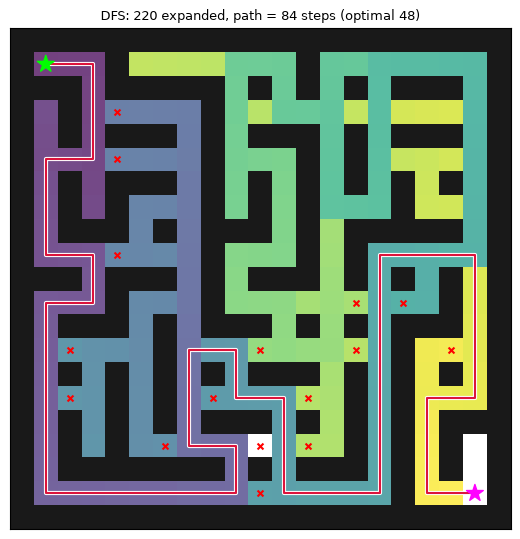

maze steps: 84 vs optimal 48 | max frontier: 35


In [8]:
def depth_first_search(problem):
    # DFS graph search with an explicit stack; goal test when a node is popped.
    stats = Stats("DFS")
    frontier = [Node(problem.initial)]          # LIFO stack
    explored = set()
    while frontier:
        stats.note_frontier(len(frontier))
        node = frontier.pop()                   # deepest (newest) node
        if problem.is_goal(node.state):
            stats.frontier_end = [n.state for n in frontier]
            return node, stats
        if node.state in explored:
            continue
        explored.add(node.state)
        stats.expanded.append(node.state)
        children = list(expand(problem, node))
        for child in reversed(children):        # reversed: first action ends on top of the stack
            if child.state not in explored:
                frontier.append(child); stats.generated += 1
    return None, stats

dfs_node, dfs_stats = depth_first_search(route)
print("DFS route:", " -> ".join(path_states(dfs_node)))
print("roads:", dfs_node.depth, "| km:", dfs_node.path_cost, "| expanded:", len(dfs_stats.expanded))

dfs_m, dfs_m_stats = depth_first_search(maze)
assert dfs_m.depth >= D_STEPS                    # DFS is not optimal: it can only be as good or worse
fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_maze(ax, dfs_m_stats, path_states(dfs_m), f"DFS: {len(dfs_m_stats.expanded)} expanded, path = {dfs_m.depth} steps (optimal {D_STEPS})", show_mud=False)
plt.tight_layout(); plt.show()
print("maze steps:", dfs_m.depth, "vs optimal", D_STEPS, "| max frontier:", dfs_m_stats.max_frontier)

**What just happened?** On the map, DFS dives Ashford → Brookvale → Dunmore → Cedar Falls → Elmstead → … and returns the first route it stumbles on: 8 roads and 276 km, almost twice the optimal 141 km. On the maze it follows one long corridor after another. The path it returns is much longer than the optimal one. DFS returns *a* solution, not the best one.

**Complexity.** Let $m$ = the **maximum depth** of the search tree (which can be much larger than $d$, or infinite).
- **Time:** $O(b^m)$: it may explore the whole tree before finding a shallow goal on the "last" branch.
- **Space:** the *tree-like* version stores only the current path plus the unexpanded siblings along it: **$O(bm)$**. This small memory is DFS's big advantage, and the reason it is the basis of IDS and of backtracking (notebook 06). Our graph-search version also keeps an explored set, which costs $O(\text{states})$ memory, so in practice you choose between "remember everything" and "use little memory".
- **Complete?** No in infinite state spaces (it can dive down an infinite branch forever). The graph-search version is complete in **finite** state spaces.
- **Optimal?** No.

> ⚠️ **Common mistake:** writing recursive DFS without any cycle check on a graph. In Python this ends in `RecursionError`; in theory it never ends.

## 6. Depth-limited search (DLS) and iterative deepening (IDS)

> 💬 **In plain English:** dive like DFS but never deeper than a limit, and raise the limit one step at a time.

**Depth-limited search** is DFS with a **depth limit** $\ell$: nodes at depth $\ell$ are treated as if they had no children. This fixes DFS's infinite-path problem, but if the shallowest goal is deeper than $\ell$, DLS cannot find it. DLS returns one of three answers:
- a **solution**;
- **cutoff**: "no solution within the limit, but I did hit the limit, so a deeper one may exist";
- **failure**: "no solution at all, and the limit was not the reason".

Like AIMA, our DLS is *tree-like*: it remembers only the current path. It checks for cycles **on the current path** (it will not walk in a circle), but it does not remember states explored on other branches. Memory stays $O(b\ell)$.

In [9]:
CUTOFF = "cutoff"                                   # a special return value

def depth_limited_search(problem, limit, stats=None):
    # Recursive DLS with a cycle check on the current path. Returns a Node, CUTOFF or None (failure).
    stats = stats or Stats(f"DLS(l={limit})")
    on_path = {problem.initial}                     # states on the current path
    def recurse(node):
        if problem.is_goal(node.state):
            return node
        if node.depth == limit:                     # hit the limit: pretend there are no children
            return CUTOFF
        stats.expanded.append(node.state)
        cutoff_happened = False
        for child in expand(problem, node):
            stats.generated += 1
            if child.state in on_path:              # would walk in a circle
                continue
            on_path.add(child.state)
            stats.note_frontier(len(on_path))       # memory: the current path (DLS keeps nothing else)
            result = recurse(child)
            on_path.discard(child.state)
            if result == CUTOFF:
                cutoff_happened = True
            elif result is not None:
                return result
        return CUTOFF if cutoff_happened else None
    return recurse(Node(problem.initial)), stats

for limit in range(0, 7):
    res, st = depth_limited_search(route, limit)
    shown = " -> ".join(path_states(res)) if isinstance(res, Node) else res
    print(f"limit {limit}: {str(shown):<70} expanded {len(st.expanded)}")

limit 0: cutoff                                                                 expanded 0
limit 1: cutoff                                                                 expanded 1
limit 2: cutoff                                                                 expanded 3
limit 3: cutoff                                                                 expanded 7
limit 4: cutoff                                                                 expanded 17
limit 5: Ashford -> Brookvale -> Dunmore -> Fairhaven -> Harborview -> Lakeside expanded 13
limit 6: Ashford -> Brookvale -> Dunmore -> Elmstead -> Glenwood -> Harborview -> Lakeside expanded 15


**What just happened?** With limits 0-4 the answer is **cutoff**: the goal is 5 roads away. From limit 5 on, DLS finds a route. Choosing $\ell$ well needs knowledge about the problem; for example, a map with 12 towns never needs a route of more than 11 roads (the **diameter** of the graph is an even better limit).

### Iterative deepening search (IDS)

**Idea:** we don't know the right limit, so try them all: $\ell = 0, 1, 2, \dots$ until a solution is found. It sounds wasteful, because each round redoes all the work of the previous ones. But in a tree with branching factor $b$, most nodes are in the **bottom level**, so the repeated upper levels cost little:

$$N(\text{IDS}) = (d)\,b + (d-1)\,b^2 + \dots + (1)\,b^d = O(b^d), \qquad N(\text{BFS}) = b + b^2 + \dots + b^d.$$

IDS combines **BFS's completeness and optimality** (for unit costs) with **DFS's $O(bd)$ memory**. AIMA: *"In general, iterative deepening is the preferred uninformed search method when the search state space is larger than can fit in memory and the depth of the solution is not known."*

In [10]:
def n_bfs(b, d):  return sum(b ** i for i in range(1, d + 1))                 # nodes generated by BFS
def n_ids(b, d):  return sum((d + 1 - i) * b ** i for i in range(1, d + 1))   # level i is generated d+1-i times

rows = [(b, d, n_bfs(b, d), n_ids(b, d), n_ids(b, d) / n_bfs(b, d)) for b, d in [(2, 10), (3, 10), (10, 5), (10, 10)]]
print(pd.DataFrame(rows, columns=["b", "d", "BFS nodes", "IDS nodes", "IDS / BFS"]).round(3).to_string(index=False))
assert n_bfs(10, 5) == 111_110 and n_ids(10, 5) == 123_450      # AIMA's numbers

 b  d   BFS nodes   IDS nodes  IDS / BFS
 2 10        2046        4072      1.990
 3 10       88572      132843      1.500
10  5      111110      123450      1.111
10 10 11111111110 12345679000      1.111


**What just happened?** For $b = 10$, $d = 5$, IDS generates 123,450 nodes against BFS's 111,110: only about 11% more, matching AIMA. The overhead ratio tends to $b/(b-1)$ as $d$ grows, so the larger the branching factor, the cheaper the repetition. For $b = 2$ it is about 2×.

Now the code. IDS just calls DLS with growing limits.

In [11]:
def iterative_deepening_search(problem, max_limit=500):
    stats = Stats("IDS")
    per_round = []                                     # nodes expanded in each round
    for limit in range(max_limit + 1):
        before = len(stats.expanded)
        result, _ = depth_limited_search(problem, limit, stats)   # shares the same Stats object
        per_round.append(len(stats.expanded) - before)
        if result != CUTOFF:
            return result, stats, per_round
    return None, stats, per_round

ids_node, ids_stats, rounds = iterative_deepening_search(route)
print("IDS route:", " -> ".join(path_states(ids_node)), "| roads:", ids_node.depth, "| km:", ids_node.path_cost)
print("expansions per round:", rounds)
assert ids_node.depth == nx.shortest_path_length(G_map, "Ashford", "Lakeside")

t0 = time.perf_counter()
ids_m, ids_m_stats, ids_rounds = iterative_deepening_search(maze)
ids_time = time.perf_counter() - t0
assert ids_m.depth == D_STEPS                        # IDS is optimal for unit costs
print(f"\nmaze: path {ids_m.depth} steps (optimal {D_STEPS}), total expansions {len(ids_m_stats.expanded):,}, "
      f"distinct squares {len(set(ids_m_stats.expanded))}, time {ids_time:.1f}s")

IDS route: Ashford -> Brookvale -> Dunmore -> Fairhaven -> Harborview -> Lakeside | roads: 5 | km: 172
expansions per round: [0, 1, 3, 7, 17, 13]



maze: path 48 steps (optimal 48), total expansions 243,596, distinct squares 221, time 5.6s


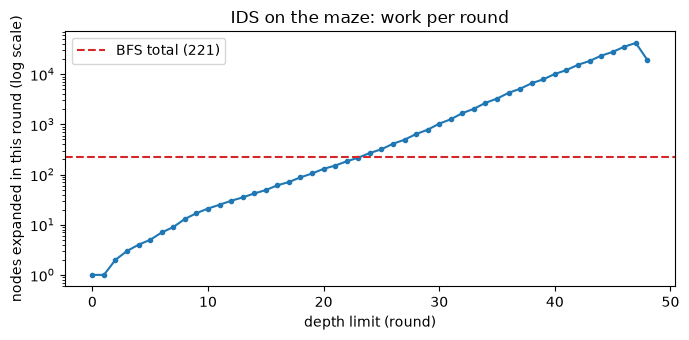

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(range(len(ids_rounds)), np.maximum(ids_rounds, 1), marker=".")
ax.axhline(len(bfs_m_stats.expanded), color="tab:red", ls="--", label=f"BFS total ({len(bfs_m_stats.expanded)})")
ax.set_xlabel("depth limit (round)"); ax.set_ylabel("nodes expanded in this round (log scale)")
ax.set_title("IDS on the maze: work per round"); ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** IDS found an optimal path, as promised, but on the maze it expanded **hundreds of thousands** of nodes, while BFS expanded only a couple of hundred. Why does this differ from the cheerful table above?

- The $b/(b-1)$ analysis assumes the state space is a **tree** (each state reachable by one path). The maze has **loops**: 25 extra holes create a huge number of different *simple paths* to the same squares. Tree-like DLS cannot tell that it has visited a square before on another branch, so it re-explores it once per path.
- The log-scale plot shows the work per round growing exponentially, exactly the "repeated states" explosion of Section 2.

**Lesson:** IDS is excellent on tree-shaped state spaces with large $b$ (such as the 8-puzzle in Section 9). On graphs with many redundant paths and enough memory, BFS or UCS with a reached set is far better.

**Complexity of IDS:** time $O(b^d)$, space $O(bd)$, complete (if $b$ is finite) and optimal for unit action costs.

## 7. Uniform-cost search (UCS)

> 💬 **In plain English:** always continue the cheapest route found so far, so the first route that reaches the goal is the cheapest one.

**Intuition.** BFS spreads out by *number of steps*. UCS spreads out by *cost*: it always expands the node with the **lowest path cost $g(n)$** so far. Think of water flowing out from the start along roads, reaching nearer towns (in km) first. This is **Dijkstra's algorithm** (1959), stopped as soon as the goal is reached.

**Definition.** **Uniform-cost search** expands the node with the lowest $g(n)$, using a **priority queue** as the frontier.

Two details that matter:
1. **Goal test when a node is *removed* (expanded), not when it is generated.** The first path found to the goal may not be the cheapest. A cheaper one may still be waiting in the queue.
2. If a cheaper path to an already-seen state is found, we keep the cheaper one. We do this with "lazy deletion": push the new entry, and skip stale entries when they are popped.

**Worked example by hand** (frontier written as `town:g`, smallest first):

| Step | Pop (expand) | Frontier after |
|---|---|---|
| 1 | Ashford:0 | Brookvale:26, Cedar Falls:28 |
| 2 | Brookvale:26 | Cedar Falls:28, Dunmore:51 |
| 3 | Cedar Falls:28 | Dunmore:51, Elmstead:52, Ironbridge:62 (Dunmore via Cedar Falls = 68, worse, ignored) |
| 4 | Dunmore:51 | Elmstead:52, Ironbridge:62, Fairhaven:78 |
| ... | ... | ... |

In [13]:
def uniform_cost_search(problem, trace=None):
    # UCS / Dijkstra with lazy deletion; goal test on expansion.
    stats = Stats("UCS")
    counter = itertools.count()                       # tie-breaker so heapq never compares Nodes
    start = Node(problem.initial)
    frontier = [(0, next(counter), start)]            # priority queue of (g, tie, node)
    best_g = {problem.initial: 0}                     # cheapest known cost to each state
    while frontier:
        stats.note_frontier(len(frontier))
        g, _, node = heapq.heappop(frontier)          # cheapest node
        if g > best_g[node.state]:                    # stale entry: a cheaper path was found later
            continue
        if problem.is_goal(node.state):               # goal test on EXPANSION
            stats.frontier_end = [n.state for _, _, n in frontier]
            if trace is not None: trace.append((f"{node.state}:{g}", "GOAL"))
            return node, stats
        stats.expanded.append(node.state)
        for child in expand(problem, node):
            stats.generated += 1
            s = child.state
            if s not in best_g or child.path_cost < best_g[s]:     # new state, or a cheaper path
                best_g[s] = child.path_cost
                heapq.heappush(frontier, (child.path_cost, next(counter), child))
        if trace is not None:
            live = sorted((gg, n.state) for gg, _, n in frontier if gg == best_g[n.state])
            trace.append((f"{node.state}:{g}", ", ".join(f"{s}:{gg}" for gg, s in live)))
    return None, stats

trace = []
ucs_node, ucs_stats = uniform_cost_search(route, trace)
print(pd.DataFrame(trace, columns=["pop", "frontier after"]).to_string())
print("\nUCS route:", " -> ".join(path_states(ucs_node)), "| km:", ucs_node.path_cost)
assert ucs_node.path_cost == nx.shortest_path_length(G_map, "Ashford", "Lakeside", weight="weight")
print("matches networkx Dijkstra:", nx.shortest_path_length(G_map, "Ashford", "Lakeside", weight="weight"), "km")

               pop                                        frontier after
0        Ashford:0                          Brookvale:26, Cedar Falls:28
1     Brookvale:26                            Cedar Falls:28, Dunmore:51
2   Cedar Falls:28                Dunmore:51, Elmstead:52, Ironbridge:62
3       Dunmore:51              Elmstead:52, Ironbridge:62, Fairhaven:78
4      Elmstead:52  Ironbridge:62, Fairhaven:78, Juniper:82, Glenwood:83
5    Ironbridge:62                 Fairhaven:78, Juniper:82, Glenwood:83
6     Fairhaven:78               Juniper:82, Glenwood:83, Harborview:108
7       Juniper:82            Glenwood:83, Harborview:108, Kingsport:120
8      Glenwood:83                         Harborview:108, Kingsport:112
9   Harborview:108                           Kingsport:112, Lakeside:172
10   Kingsport:112                                          Lakeside:141
11    Lakeside:141                                                  GOAL

UCS route: Ashford -> Cedar Falls -> Elmstead -> G

**What just happened?** UCS pulled towns out of the queue in order of distance from Ashford. Look at the trace: **Lakeside entered the frontier at 172 km** (via Harborview) before the 141 km route was known. If we had stopped at generation, as BFS does, we would have returned the wrong route. Because UCS waits until Lakeside is the *cheapest* thing in the queue, it returns the optimal **141 km** route via Glenwood and Kingsport, and the assert confirms it against NetworkX's Dijkstra.

Now the muddy maze, where BFS and UCS disagree.

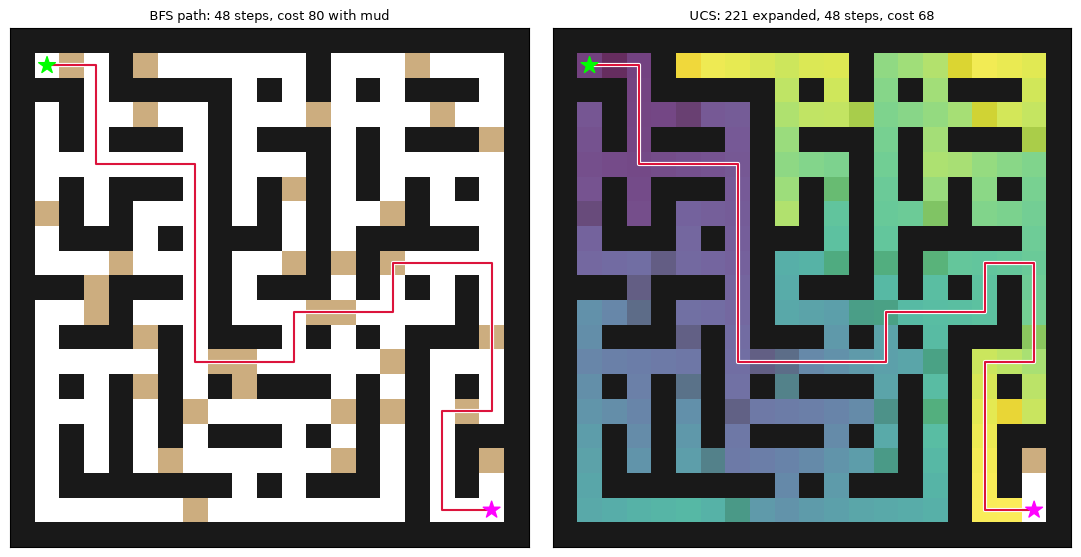

BFS: 48 steps, cost 80 | UCS: 48 steps, cost 68 (networkx: 68)


In [14]:
ucs_m, ucs_m_stats = uniform_cost_search(muddy_maze)
assert ucs_m.path_cost == C_STAR                                   # cost-optimal
bfs_cost_in_mud = sum(int(COSTS[s]) for s in bfs_path[1:])          # BFS's path priced with mud
assert bfs_cost_in_mud >= C_STAR
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
draw_maze(axes[0], None, bfs_path, f"BFS path: {len(bfs_path) - 1} steps, cost {bfs_cost_in_mud} with mud")
draw_maze(axes[1], ucs_m_stats, path_states(ucs_m), f"UCS: {len(ucs_m_stats.expanded)} expanded, {ucs_m.depth} steps, cost {ucs_m.path_cost}")
plt.tight_layout(); plt.show()
print(f"BFS: {len(bfs_path) - 1} steps, cost {bfs_cost_in_mud} | UCS: {ucs_m.depth} steps, cost {ucs_m.path_cost} (networkx: {C_STAR})")

**What just happened?** BFS's path is the shortest in **steps** but walks through mud. UCS takes a path with at least as many steps that avoids the expensive squares, and it has the lowest **cost**, exactly matching NetworkX.

**Complexity.** Let $C^*$ = the cost of the optimal solution and $\epsilon$ = the smallest action cost ($\epsilon > 0$). UCS may explore every node with $g < C^*$. In the worst case that is a tree of depth about $1 + \lfloor C^*/\epsilon \rfloor$, so **time and space are $O(b^{1 + \lfloor C^*/\epsilon \rfloor})$**. With a binary heap, each push and pop costs $O(\log n)$. When all costs are equal, this becomes $O(b^{d+1})$: UCS is then slightly *worse* than BFS, because it waits to goal-test until expansion.

- **Complete?** Yes, if every action cost is at least some $\epsilon > 0$ (otherwise a loop of zero-cost actions can trap it).
- **Optimal?** Yes. Nodes are expanded in order of $g$, so the first time the goal is expanded, no cheaper path can exist.

> ⚠️ **Common mistake:** goal-testing on generation in UCS (copying BFS's early test). It breaks optimality, as the 172 km vs 141 km trace shows.

## 8. Bidirectional BFS

> 💬 **In plain English:** search from the start and from the goal at the same time, and stop when the two searches meet.

**Intuition.** Two teams dig a tunnel from both sides of a mountain and meet in the middle. Two searches, each of depth $d/2$, do far less work than one of depth $d$: $2 \cdot b^{d/2} \ll b^d$. For $b = 10$, $d = 6$: $2{,}000$ vs $1{,}000{,}000$.

**Requirements.** We must be able to search **backwards** from the goal. That needs (1) one explicit goal state (or a small set), and (2) a way to compute **predecessors**. In our map and maze every action can be undone, so predecessors = successors.

**Stopping rule** (the subtle part). We expand one *whole layer* at a time, always on the side with the smaller frontier. As soon as a newly generated state has already been reached by the other side, the two searches have met. We then take the meeting state with the smallest total `forward depth + backward depth` within that layer. Stopping at the first meeting state without checking the rest of the layer can give a non-optimal path.

bidirectional route: Ashford -> Brookvale -> Dunmore -> Fairhaven -> Harborview -> Lakeside | roads: 5 | expanded: 6 + 3


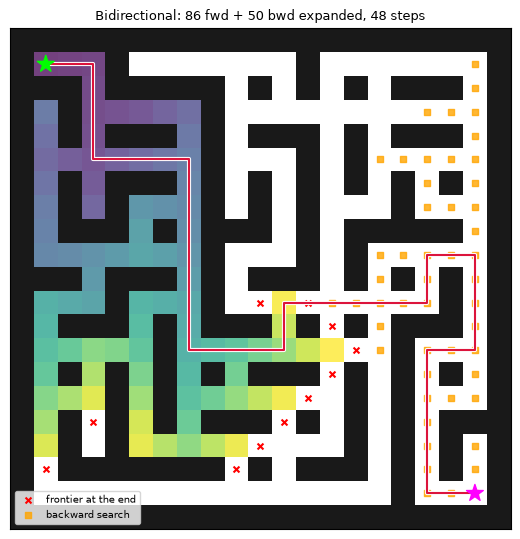

In [15]:
def bidirectional_bfs(problem, start, goal):
    # Layer-by-layer bidirectional BFS for problems whose actions are reversible (predecessors = successors).
    fwd, bwd = Stats("Bidirectional (forward)"), Stats("Bidirectional (backward)")
    if start == goal:
        return [start], fwd, bwd
    parent_f, parent_b = {start: None}, {goal: None}        # reached sets + parent pointers
    depth_f, depth_b = {start: 0}, {goal: 0}
    frontier_f, frontier_b = deque([start]), deque([goal])

    def successors(s):
        return [problem.result(s, a) for a in problem.actions(s)]

    def expand_layer(frontier, parent, depth, other_depth, stats):
        # Expand every node in the current layer; return the meeting states found in this layer.
        meets = []
        for _ in range(len(frontier)):
            s = frontier.popleft()
            stats.expanded.append(s)
            for s2 in successors(s):
                stats.generated += 1
                if s2 not in parent:
                    parent[s2] = s; depth[s2] = depth[s] + 1
                    frontier.append(s2)
                    if s2 in other_depth:
                        meets.append(s2)
        return meets

    while frontier_f and frontier_b:
        fwd.note_frontier(len(frontier_f)); bwd.note_frontier(len(frontier_b))
        if len(frontier_f) <= len(frontier_b):              # grow the smaller side
            meets = expand_layer(frontier_f, parent_f, depth_f, depth_b, fwd)
        else:
            meets = expand_layer(frontier_b, parent_b, depth_b, depth_f, bwd)
        if meets:
            m = min(meets, key=lambda s: depth_f[s] + depth_b[s])  # best meeting point in this layer
            path, s = [], m
            while s is not None: path.append(s); s = parent_f[s]   # start ... m
            path = path[::-1]
            s = parent_b[m]
            while s is not None: path.append(s); s = parent_b[s]   # m ... goal
            fwd.frontier_end, bwd.frontier_end = list(frontier_f), list(frontier_b)
            return path, fwd, bwd
    return None, fwd, bwd

bi_route, f_st, b_st = bidirectional_bfs(route, "Ashford", "Lakeside")
print("bidirectional route:", " -> ".join(bi_route), "| roads:", len(bi_route) - 1,
      "| expanded:", len(f_st.expanded), "+", len(b_st.expanded))
assert len(bi_route) - 1 == nx.shortest_path_length(G_map, "Ashford", "Lakeside")

bi_path, bf, bb = bidirectional_bfs(maze, START, GOAL)
assert len(bi_path) - 1 == D_STEPS                              # optimal number of steps
assert all(abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1 for a, b in zip(bi_path, bi_path[1:]))  # a real path
fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_maze(ax, bf, bi_path, f"Bidirectional: {len(bf.expanded)} fwd + {len(bb.expanded)} bwd expanded, {len(bi_path) - 1} steps",
          show_mud=False, second=bb)
legend_if_any(ax); plt.tight_layout(); plt.show()

**What just happened?** The forward search (coloured) and the backward search (orange squares) each covered part of the maze and met in the middle. The path is optimal (checked against NetworkX). It also passed a second check: every step moves to an adjacent square.

In a narrow maze the saving is modest, because the number of squares at distance $k$ grows slowly. In problems where the number of states grows exponentially with depth, the saving is dramatic. Section 9 shows this on the 8-puzzle.

**Complexity:** time and space $O(b^{d/2})$. It is complete and optimal for unit costs when both halves are BFS. **Space** is the catch: at least one side's reached set must be kept in memory to detect the meeting.

> 🎓 **Exam / interview tip:** "Why not always use bidirectional search?" Because (1) you need predecessors, which can be hard to compute (in chess, which positions lead to checkmate?), (2) the goal may be a *description* ("any checkmate"), not one state, and (3) it needs memory for the reached sets.

## 9. The race

> 💬 **In plain English:** all six algorithms on the same maze and on the 8-puzzle, with the numbers side by side.

### 9.1 All six on the maze

We run every algorithm on the same maze and collect the numbers. DLS gets limit $\ell = 40$, which is too small (the goal is further away), to show the "cutoff" answer.

In [16]:
dls_m, dls_m_stats = depth_limited_search(maze, 40)
runs = {
    "BFS": (bfs_m_stats, bfs_path),
    "DFS": (dfs_m_stats, path_states(dfs_m)),
    "DLS (l = 40)": (dls_m_stats, path_states(dls_m) if isinstance(dls_m, Node) else None),
    "IDS": (ids_m_stats, path_states(ids_m)),
    "UCS (mud costs)": (ucs_m_stats, path_states(ucs_m)),
    "Bidirectional BFS": (bf, bi_path),
}
def cost_with_mud(path):
    return sum(int(COSTS[s]) for s in path[1:]) if path else None

rows = []
for name, (st, path) in runs.items():
    expanded = len(st.expanded) + (len(bb.expanded) if name.startswith("Bidir") else 0)
    rows.append({"algorithm": name,
                 "found?": path is not None if name != "DLS (l = 40)" else str(dls_m),
                 "steps": len(path) - 1 if path else None,
                 "cost with mud": cost_with_mud(path),
                 "nodes expanded": expanded,
                 "distinct squares expanded": len(set(st.expanded)) + (len(set(bb.expanded)) if name.startswith("Bidir") else 0),
                 "max frontier (DLS/IDS: max path)": st.max_frontier + (bb.max_frontier if name.startswith("Bidir") else 0)})
race = pd.DataFrame(rows).set_index("algorithm")
print(race.to_string())
print(f"\noptimal steps (networkx) = {D_STEPS}, optimal cost with mud (networkx) = {C_STAR}")

# The guarantees from theory, checked:
assert race.loc["BFS", "steps"] == race.loc["IDS", "steps"] == race.loc["Bidirectional BFS", "steps"] == D_STEPS
assert race.loc["UCS (mud costs)", "cost with mud"] == C_STAR
assert race.loc["DFS", "steps"] >= D_STEPS and dls_m == CUTOFF

                   found?  steps  cost with mud  nodes expanded  distinct squares expanded  max frontier (DLS/IDS: max path)
algorithm                                                                                                                   
BFS                  True   48.0           80.0             221                        221                                12
DFS                  True   84.0          140.0             220                        220                                35
DLS (l = 40)       cutoff    NaN            NaN           10113                        201                                41
IDS                  True   48.0           80.0          243596                        221                                49
UCS (mud costs)      True   48.0           68.0             221                        221                                13
Bidirectional BFS    True   48.0           72.0             136                        136                                18


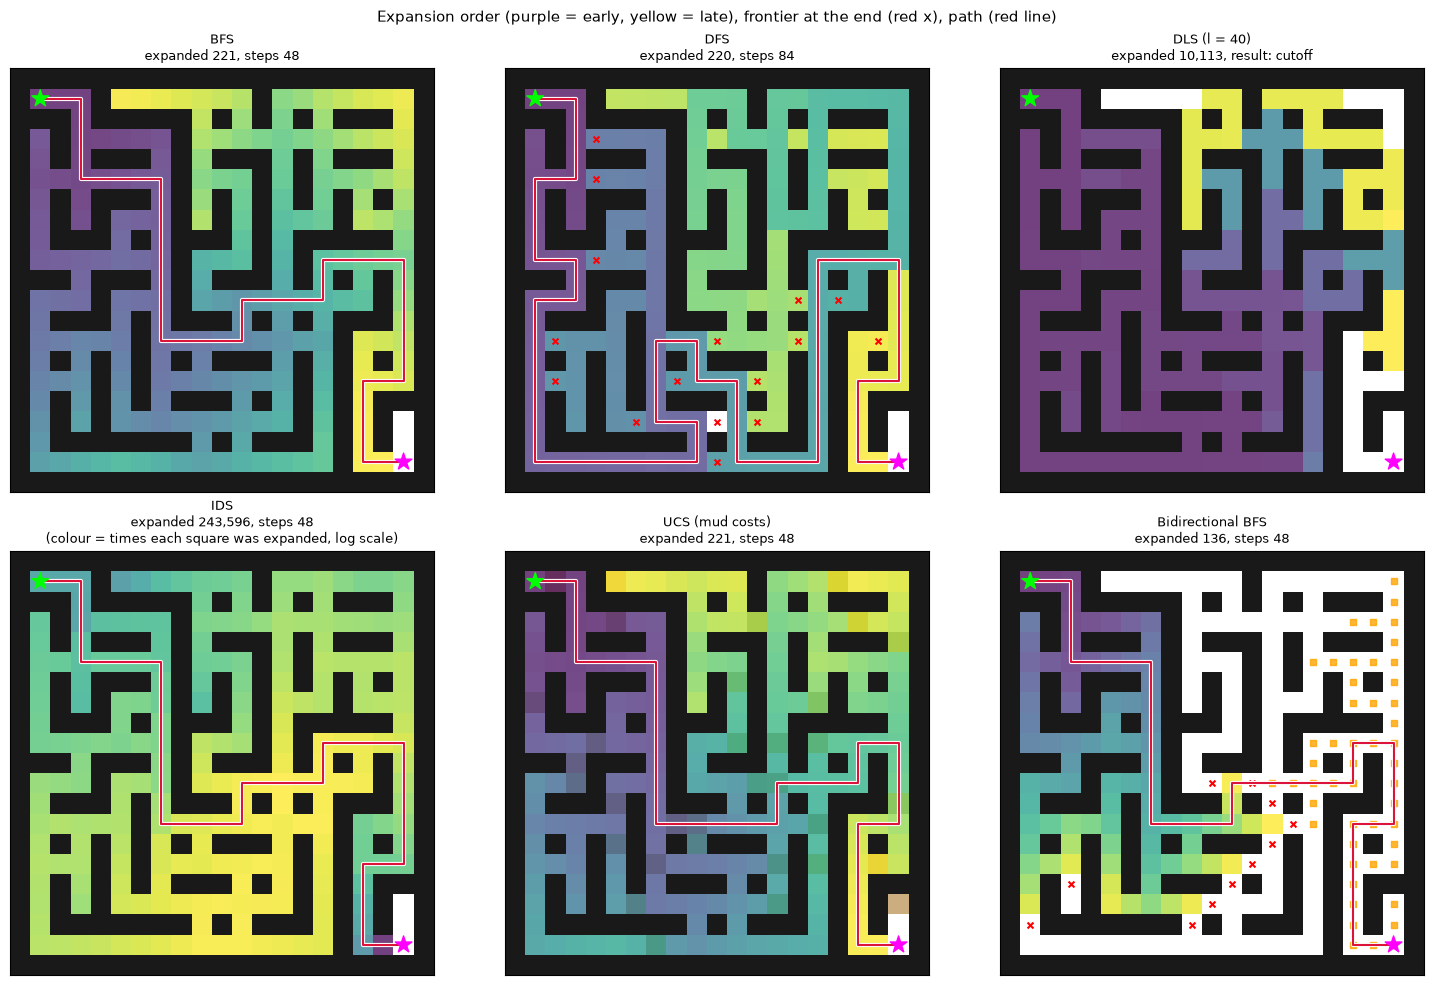

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (name, (st, path)) in zip(axes.ravel(), runs.items()):
    second = bb if name.startswith("Bidir") else None
    label = f"{name}\nexpanded {race.loc[name, 'nodes expanded']:,}"
    label += f", steps {race.loc[name, 'steps']:.0f}" if path else ", result: cutoff"
    if name == "IDS":
        label += "\n(colour = times each square was expanded, log scale)"
    draw_maze(ax, st, path, label, show_mud=name.startswith("UCS"), second=second, by_count=(name == "IDS"))
plt.suptitle("Expansion order (purple = early, yellow = late), frontier at the end (red x), path (red line)", fontsize=11)
plt.tight_layout(); plt.show()

**What just happened?** One picture per algorithm, the same maze each time:
- **BFS** spreads evenly by distance.
- **DFS** follows a few long corridors and returns a long path.
- **DLS** with a limit that is too small explores everything within 40 steps and then answers **cutoff**.
- **IDS** reaches the same squares as BFS, but it expanded vastly more *nodes*: each square was expanded again and again, once per path and once per round. Its picture is coloured by **how many times** each square was expanded. On average each square was expanded more than 1,000 times (243,596 expansions / 221 squares). The yellow squares, in the part of the maze with many loops, were expanded the most, because many different loop-free paths reach them.
- The "max frontier" column measures memory. For DLS and IDS it is the longest path held in memory: they never store more than one path, plus the siblings waiting on it.
- **UCS** spreads by *cost*: the mud squares slow its "ripple" down.
- **Bidirectional BFS** grows two smaller regions that meet in the middle.

All the guarantees from theory hold, and the asserts check them: BFS, IDS and bidirectional BFS find the fewest steps; UCS finds the lowest cost; DFS finds a valid but longer path.

### 9.2 The 8-puzzle: where bidirectional search and IDS shine

The 8-puzzle's state space grows exponentially with depth. Each state has 2-4 moves; after excluding the move that undoes the previous one, the search tree grows by a factor of about 1.7 per level. It also contains far fewer short loops than our maze: the shortest cycle takes 12 moves. We generate puzzles of known difficulty: a BFS backwards from the goal over all 181,440 reachable states gives the exact distance $d$ of every state.

In [18]:
class EightPuzzle(Problem):
    GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)
    DELTAS = {"Up": -3, "Down": 3, "Left": -1, "Right": 1}
    def __init__(self, initial):
        super().__init__(initial, self.GOAL)
    def actions(self, s):
        r, c = divmod(s.index(0), 3)
        return [a for a, ok in (("Up", r > 0), ("Down", r < 2), ("Left", c > 0), ("Right", c < 2)) if ok]
    def result(self, s, a):
        i = s.index(0); j = i + self.DELTAS[a]
        t = list(s); t[i], t[j] = t[j], t[i]
        return tuple(t)

# Exact distance-to-goal for every reachable state (one BFS from the goal; moves are reversible).
dist_to_goal = {EightPuzzle.GOAL: 0}
queue = deque([EightPuzzle.GOAL])
helper = EightPuzzle(EightPuzzle.GOAL)
while queue:
    s = queue.popleft()
    for a in helper.actions(s):
        s2 = helper.result(s, a)
        if s2 not in dist_to_goal:
            dist_to_goal[s2] = dist_to_goal[s] + 1; queue.append(s2)
print("reachable states:", len(dist_to_goal), "| hardest puzzles need", max(dist_to_goal.values()), "moves")

by_depth = {}
for s, d in dist_to_goal.items():
    by_depth.setdefault(d, []).append(s)
rng = random.Random(SEED)
rows = []
for d in (4, 8, 12, 16, 20):
    for s in rng.sample(by_depth[d], 3):                      # 3 random puzzles of exactly depth d
        p = EightPuzzle(s)
        n_b, st_b = breadth_first_search(p)
        path_bi, f8, b8 = bidirectional_bfs(p, s, EightPuzzle.GOAL)
        assert n_b.depth == d and len(path_bi) - 1 == d      # both optimal
        row = {"d": d, "BFS expanded": len(st_b.expanded),
               "bidirectional expanded": len(f8.expanded) + len(b8.expanded)}
        if d <= 12:                                           # IDS gets slow beyond this in Python
            n_i, st_i, _ = iterative_deepening_search(p)
            assert n_i.depth == d
            row["IDS expanded"] = len(st_i.expanded)
        rows.append(row)
puzzle_table = pd.DataFrame(rows).groupby("d").mean().round(0)
print(puzzle_table.to_string())

reachable states: 181440 | hardest puzzles need 31 moves


    BFS expanded  bidirectional expanded  IDS expanded
d                                                     
4           12.0                     6.0          20.0
8          147.0                    34.0         338.0
12        1037.0                   108.0        3188.0
16        6435.0                   320.0           NaN
20       30522.0                   879.0           NaN


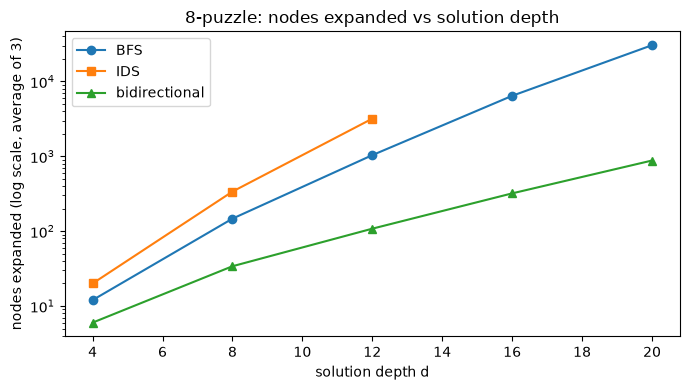

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
for col, m in [("BFS expanded", "o"), ("IDS expanded", "s"), ("bidirectional expanded", "^")]:
    ser = puzzle_table[col].dropna()
    ax.semilogy(ser.index, ser.values, marker=m, label=col.replace(" expanded", ""))
ax.set_xlabel("solution depth d"); ax.set_ylabel("nodes expanded (log scale, average of 3)")
ax.set_title("8-puzzle: nodes expanded vs solution depth"); ax.legend(); plt.tight_layout(); plt.show()

**What just happened?**
- Every answer was checked to be optimal ($d$ moves, from the exact BFS table).
- On a log scale, BFS's curve is roughly a straight line: work grows **exponentially** with depth, as $O(b^d)$ says.
- **IDS** costs a few times more than BFS here. That is the repeated-work overhead plus some loops, but nothing like the maze disaster, and it needs only $O(bd)$ memory.
- **Bidirectional BFS** is far below both, and its line has about **half the slope** of BFS's: two searches of depth $d/2$, so $O(b^{d/2})$ instead of $O(b^d)$. At $d = 20$ it expands about 35 times fewer nodes than BFS, and the gap widens with every extra move of depth.

## 10. The comparison table

> 💬 **In plain English:** one table that tells you which algorithm always finds an answer, which finds the best one, and how much time and memory each needs.

**Notation (AIMA):**
- $b$: **branching factor**, the maximum number of successors of a node
- $d$: **depth of the shallowest solution**
- $m$: **maximum depth** of the search tree (may be $\infty$)
- $\ell$: the **depth limit** of DLS
- $C^*$: **cost of the optimal solution**
- $\epsilon$: the **smallest action cost** (a positive number)

| Criterion | BFS | Uniform-cost | DFS | Depth-limited | Iterative deepening | Bidirectional (if applicable) |
|---|---|---|---|---|---|---|
| **Complete?** | Yes¹ | Yes¹˒² | No | No | Yes¹ | Yes¹˒⁴ |
| **Optimal (cost)?** | Yes³ | Yes | No | No | Yes³ | Yes³˒⁴ |
| **Time** | $O(b^d)$ | $O(b^{1+\lfloor C^*/\epsilon\rfloor})$ | $O(b^m)$ | $O(b^\ell)$ | $O(b^d)$ | $O(b^{d/2})$ |
| **Space** | $O(b^d)$ | $O(b^{1+\lfloor C^*/\epsilon\rfloor})$ | $O(bm)$ | $O(b\ell)$ | $O(bd)$ | $O(b^{d/2})$ |

¹ complete if $b$ is finite and the state space either has a solution or is finite.
² complete if all action costs are $\geq \epsilon > 0$.
³ cost-optimal if all action costs are identical.
⁴ if both directions are breadth-first or uniform-cost searches.

(This is AIMA 4th edition, Figure 3.15. DFS's $O(bm)$ space is for the *tree-like* version. A graph-search DFS also stores its explored set. A graph-search DFS is complete in finite state spaces.)

**Why each entry holds, in one line each:**
- *BFS complete:* it checks every depth level in turn, and each level is finite when $b$ is finite.
- *BFS optimal only for equal costs:* it minimises the number of steps, not the sum of costs (172 km vs 141 km).
- *UCS optimal:* it expands nodes in increasing order of $g$, so the goal is expanded first along a cheapest path.
- *DFS not complete:* it can dive forever down an infinite branch.
- *IDS space $O(bd)$:* each round is a DFS with depth at most $d$.
- *Bidirectional $O(b^{d/2})$:* two searches of depth $d/2$ each.

**Which one should I use?**

| Situation | Choose |
|---|---|
| Unit costs, enough memory | BFS (or bidirectional BFS if you can search backwards) |
| Different action costs | UCS (Dijkstra) |
| Huge or infinite space, unknown depth, little memory | IDS |
| Any solution will do, solutions are deep and plentiful, memory is tight | DFS (with a depth limit if branches can be infinite) |
| You know something about where the goal is | **informed search** (A\*, next notebook) |

## 11. Solving the water jug and missionaries & cannibals puzzles

> 💬 **In plain English:** our search code solves two classic puzzles step by step.

We reuse the formulations from notebook 01 and solve them with our own BFS, IDS and UCS, checking each answer against NetworkX on the full state graph.

In [20]:
class WaterJug(Problem):
    def __init__(self, capacities=(4, 3), target=2):
        super().__init__((0, 0)); self.cap, self.target = capacities, target
    def _apply(self, s, a):
        x, y = s; A, B = self.cap
        if a == "fill A":  return (A, y)
        if a == "fill B":  return (x, B)
        if a == "empty A": return (0, y)
        if a == "empty B": return (x, 0)
        if a == "pour A->B": t = min(x, B - y); return (x - t, y + t)
        if a == "pour B->A": t = min(y, A - x); return (x + t, y - t)
    def actions(self, s):
        names = ["fill A", "fill B", "empty A", "empty B", "pour A->B", "pour B->A"]
        return [a for a in names if self._apply(s, a) != s]
    def result(self, s, a):
        return self._apply(s, a)
    def is_goal(self, s):
        return s[0] == self.target

class MissionariesCannibals(Problem):
    def __init__(self, n=3, capacity=2):
        super().__init__((n, n, 1), (0, 0, 0)); self.n = n
        self.loads = [(dm, dc) for dm in range(capacity + 1) for dc in range(capacity + 1) if 1 <= dm + dc <= capacity]
    def safe(self, m, c):
        n = self.n
        return 0 <= m <= n and 0 <= c <= n and (m == 0 or m >= c) and (n - m == 0 or n - m >= n - c)
    def actions(self, s):
        m, c, b = s; sign = -1 if b == 1 else 1
        return [(dm, dc) for dm, dc in self.loads if self.safe(m + sign * dm, c + sign * dc)]
    def result(self, s, a):
        m, c, b = s; sign = -1 if b == 1 else 1
        return (m + sign * a[0], c + sign * a[1], 1 - b)

def full_graph(problem):
    # The whole reachable state graph, for checking with networkx.
    G, seen, queue = nx.DiGraph(), {problem.initial}, deque([problem.initial])
    G.add_node(problem.initial)
    while queue:
        s = queue.popleft()
        for a in problem.actions(s):
            s2 = problem.result(s, a); G.add_edge(s, s2)
            if s2 not in seen: seen.add(s2); queue.append(s2)
    return G

jug = WaterJug()
node, st = breadth_first_search(jug)
print("Water jug (4 L and 3 L, want 2 L in the 4-L jug), BFS solution:")
state = jug.initial
for i, a in enumerate(path_actions(node), 1):
    state = jug.result(state, a)
    print(f"  {i}. {a:<10} -> 4-L jug: {state[0]} L, 3-L jug: {state[1]} L")
Gj = full_graph(jug)
best = min(nx.shortest_path_length(Gj, jug.initial, g) for g in Gj if jug.is_goal(g))
for solver in (breadth_first_search, uniform_cost_search, lambda p: iterative_deepening_search(p)[:2]):
    n_, _ = solver(jug)
    assert n_.depth == best                           # all three are optimal here (unit costs)
print("optimal number of actions (networkx):", best)

Water jug (4 L and 3 L, want 2 L in the 4-L jug), BFS solution:
  1. fill A     -> 4-L jug: 4 L, 3-L jug: 0 L
  2. pour A->B  -> 4-L jug: 1 L, 3-L jug: 3 L
  3. empty B    -> 4-L jug: 1 L, 3-L jug: 0 L
  4. pour A->B  -> 4-L jug: 0 L, 3-L jug: 1 L
  5. fill A     -> 4-L jug: 4 L, 3-L jug: 1 L
  6. pour A->B  -> 4-L jug: 2 L, 3-L jug: 3 L
optimal number of actions (networkx): 6


In [21]:
mc = MissionariesCannibals()
node, st = breadth_first_search(mc)
print("Missionaries & cannibals, BFS solution (counts on the LEFT bank, then the boat's side):")
state = mc.initial
for i, (dm, dc) in enumerate(path_actions(node), 1):
    direction = "->" if state[2] == 1 else "<-"
    state = mc.result(state, (dm, dc))
    boat = "M" * dm + "C" * dc
    print(f"  {i:2d}. boat {direction} carries {boat:<2}  left bank: {state[0]}M {state[1]}C   right bank: {3 - state[0]}M {3 - state[1]}C")
Gm = full_graph(mc)
assert node.depth == nx.shortest_path_length(Gm, mc.initial, mc.goal) == 11
ids_mc, ids_mc_stats, _ = iterative_deepening_search(mc)
dfs_mc, dfs_mc_stats = depth_first_search(mc)
print(f"\nBFS: {node.depth} crossings, {len(st.expanded)} expanded | IDS: {ids_mc.depth} crossings, "
      f"{len(ids_mc_stats.expanded)} expanded | DFS: {dfs_mc.depth} crossings, {len(dfs_mc_stats.expanded)} expanded")
assert ids_mc.depth == 11

Missionaries & cannibals, BFS solution (counts on the LEFT bank, then the boat's side):
   1. boat -> carries CC  left bank: 3M 1C   right bank: 0M 2C
   2. boat <- carries C   left bank: 3M 2C   right bank: 0M 1C
   3. boat -> carries CC  left bank: 3M 0C   right bank: 0M 3C
   4. boat <- carries C   left bank: 3M 1C   right bank: 0M 2C
   5. boat -> carries MM  left bank: 1M 1C   right bank: 2M 2C
   6. boat <- carries MC  left bank: 2M 2C   right bank: 1M 1C
   7. boat -> carries MM  left bank: 0M 2C   right bank: 3M 1C
   8. boat <- carries C   left bank: 0M 3C   right bank: 3M 0C
   9. boat -> carries CC  left bank: 0M 1C   right bank: 3M 2C
  10. boat <- carries C   left bank: 0M 2C   right bank: 3M 1C
  11. boat -> carries CC  left bank: 0M 0C   right bank: 3M 3C

BFS: 11 crossings, 13 expanded | IDS: 11 crossings, 135 expanded | DFS: 11 crossings, 12 expanded


**What just happened?**
- **Water jug:** BFS found a 6-action solution, matching the shortest path in the full state graph. UCS and IDS agree, since all actions cost 1. Notice the trick: we can never measure 2 L directly, so we use the difference $3 + 3 - 4 = 2$.
- **Missionaries & cannibals:** BFS found the classic **11-crossing** solution, which matches NetworkX. The tricky moment is crossing 6: a missionary and a cannibal row *back* to the start bank. It looks like a step away from the goal, but it is the only safe move. Search does not mind such moves, because it does not judge states by how close they *look* to the goal. Even DFS returns 11 crossings here, because the state space is a narrow corridor with very few branches.

These puzzles are tiny (14 and 16 states), so every algorithm is instant. The algorithms only start to differ when the state space is big, as in the maze and the 8-puzzle.

## 12. 🔗 How this connects to modern AI

> 💬 **In plain English:** the same searches run inside map apps, web crawlers, chess engines and LLM agents.

- **BFS and Dijkstra run the internet and your maps.** Internet routing protocols such as OSPF run Dijkstra's algorithm (UCS without a goal) on the network graph. Social networks use BFS for "people within 2 connections". Garbage collectors in Python and Java use graph traversal to find reachable objects.
- **Web crawlers** are BFS over hyperlinks with a reached set, the same pattern as our `breadth_first_search`. The crawls that collect training text for LLMs work this way.
- **Iterative deepening is inside every chess engine.** Engines search to depth 1, 2, 3, … until their time runs out, so they always have a move ready. That is an *anytime* algorithm (notebook 05).
- **LLM agents search too.** "Tree of Thoughts"-style methods explore reasoning steps with BFS or DFS over partial solutions, and agent planners explore sequences of tool calls. See [`10_Agents/02_memory_and_planning.ipynb`](../../10_Agents/02_memory_and_planning.ipynb) and [`08_LLM/18_reasoning_models.ipynb`](../../08_LLM/18_reasoning_models.ipynb).
- **Reinforcement learning** uses the same state/action/transition model. Dynamic programming in [`11_Reinforcement_Learning/02_dynamic_programming.ipynb`](../../11_Reinforcement_Learning/02_dynamic_programming.ipynb) sweeps over all states, much like a BFS from every state at once.

## 13. Recap

> 💬 **In plain English:** the key ideas of this notebook in a few bullets, then practice.

- Search builds a **tree of nodes** over the **state-space graph**. A node stores a state, its parent, the action and the path cost $g$.
- **Graph search** keeps an explored/reached set and never expands a state twice. **Tree search** does not, and can blow up or loop forever on graphs with cycles.
- The frontier's data structure *is* the strategy: **FIFO → BFS**, **LIFO → DFS**, **priority queue on $g$ → UCS**.
- **BFS**: complete, optimal for equal costs, but $O(b^d)$ memory. **DFS**: small memory $O(bm)$, but neither complete nor optimal. **DLS** adds a limit. **IDS** repeats DLS with growing limits: BFS's guarantees with DFS's memory. **UCS** (Dijkstra) is optimal for any positive costs, provided the goal test happens on expansion. **Bidirectional** search does $O(b^{d/2})$ work but needs predecessors and an explicit goal.
- Tree-like searches such as IDS can **explode on graphs with many loops**. Repeated states matter in practice, not just in theory.
- We verified every optimality claim with `assert` against NetworkX, on a road map, a muddy maze, the 8-puzzle, the water jug and missionaries & cannibals.

## Practice problems

**1. (Easy)** In the graph `A-B, A-C, B-D, C-D, D-E` (neighbours in alphabetical order), list the order in which BFS and DFS (graph search, goal test on removal) **expand** nodes when searching from `A` to `E`.

<details><summary>Show solution</summary>

- **BFS:** A, B, C, D, then E is removed and recognised as the goal. With the early goal test, E is found while expanding D, so the expanded nodes are A, B, C, D.
- **DFS** (first neighbour first): A, B, D, then E is removed as the goal. C is never expanded.

</details>

**2. (Easy)** Why must uniform-cost search apply the goal test when a node is *expanded* and not when it is *generated*? Give a 3-node example.

<details><summary>Show solution</summary>

Graph: `S→G` costs 10, `S→A` costs 1, `A→G` costs 1. Expanding S generates G with $g = 10$ and A with $g = 1$. Testing on generation would return the 10-cost path. UCS instead expands A next ($g = 1$), generates G with $g = 2$, and pops G at cost 2: the optimal path. Our road-map trace showed the same effect: Lakeside first appeared at 172 km, while the optimum is 141 km.

</details>

**3. (Easy, coding)** Use the formulas from Section 6 to compute the nodes generated by BFS and IDS for $b = 2$, $d = 10$. Why is the overhead bigger than for $b = 10$?

<details><summary>Show solution</summary>

```python
def n_bfs(b, d): return sum(b ** i for i in range(1, d + 1))
def n_ids(b, d): return sum((d + 1 - i) * b ** i for i in range(1, d + 1))
print(n_bfs(2, 10), n_ids(2, 10), round(n_ids(2, 10) / n_bfs(2, 10), 3))   # 2046 4072 1.99
assert (n_bfs(2, 10), n_ids(2, 10)) == (2046, 4072)
```

The overhead ratio approaches $b/(b-1)$. For $b = 2$ that is 2, because the bottom level holds only about half of all nodes, so repeating the upper levels doubles the work. For $b = 10$ the bottom level holds about 90% of the nodes.

</details>

**4. (Medium, coding)** Modify BFS to **count** the number of different shortest paths from start to goal. Test it on a 4 × 4 open grid from corner to corner (the answer is $\binom{6}{3} = 20$).

<details><summary>Show solution</summary>

```python
from collections import deque
import networkx as nx

def count_shortest_paths(graph, start, goal):
    """Number of different shortest (fewest-edge) paths, using BFS layers."""
    dist, ways = {start: 0}, {start: 1}
    queue = deque([start])
    while queue:
        u = queue.popleft()
        for v in graph[u]:
            if v not in dist:                      # first time: one layer deeper
                dist[v] = dist[u] + 1; ways[v] = ways[u]; queue.append(v)
            elif dist[v] == dist[u] + 1:           # another shortest way into v
                ways[v] += ways[u]
    return ways.get(goal, 0)

G = nx.grid_2d_graph(4, 4)                           # 4x4 open grid
n = count_shortest_paths(G, (0, 0), (3, 3))
assert n == len(list(nx.all_shortest_paths(G, (0, 0), (3, 3)))) == 20   # C(6,3) = 20
print(n)
```

</details>

**5. (Medium, coding)** Write a **recursive** DFS that checks for cycles on the current path, and run it on a small graph.

<details><summary>Show solution</summary>

```python
def dfs_recursive(graph, state, goal, on_path=None):
    """Recursive DFS with a cycle check on the current path. Returns a list of states or None."""
    on_path = on_path or [state]
    if state == goal:
        return list(on_path)
    for nxt in sorted(graph[state]):
        if nxt not in on_path:                 # do not walk in a circle
            on_path.append(nxt)
            found = dfs_recursive(graph, nxt, goal, on_path)
            if found:
                return found
            on_path.pop()
    return None

roads = {"A": ["B", "C"], "B": ["A", "D"], "C": ["A", "D"], "D": ["B", "C", "E"], "E": ["D"]}
print(dfs_recursive(roads, "A", "E"))          # ['A', 'B', 'D', 'E']
assert dfs_recursive(roads, "A", "E") == ["A", "B", "D", "E"]
```

</details>

**6. (Hard, coding)** Implement **bidirectional uniform-cost search** (bidirectional Dijkstra) and test it against NetworkX on 200 random weighted graphs. *Hint:* you cannot stop at the first meeting. Keep the best complete path cost $\mu$ found so far, and stop when the smallest $g$ in the forward queue plus the smallest $g$ in the backward queue is at least $\mu$.

<details><summary>Show solution</summary>

```python
import heapq, random
import networkx as nx

def bidirectional_ucs(adj, start, goal):
    """Bidirectional Dijkstra on an undirected weighted graph adj[u][v] = cost. Returns the optimal cost."""
    if start == goal:
        return 0
    dist = [{start: 0}, {goal: 0}]                    # 0 = forward, 1 = backward
    heaps = [[(0, start)], [(0, goal)]]
    done = [set(), set()]
    best = float("inf")                               # best complete path found so far (mu)
    while heaps[0] and heaps[1]:
        # Stopping rule: no path through unexpanded nodes can beat `best`.
        if heaps[0][0][0] + heaps[1][0][0] >= best:
            break
        side = 0 if heaps[0][0][0] <= heaps[1][0][0] else 1
        g, u = heapq.heappop(heaps[side])
        if u in done[side] or g > dist[side][u]:
            continue
        done[side].add(u)
        for v, w in adj[u].items():
            ng = g + w
            if ng < dist[side].get(v, float("inf")):
                dist[side][v] = ng
                heapq.heappush(heaps[side], (ng, v))
            if v in dist[1 - side]:                    # a complete path start..u-v..goal
                best = min(best, ng + dist[1 - side][v])
    return best

rng = random.Random(0)
for trial in range(200):                                # test against networkx on random graphs
    G = nx.gnm_random_graph(30, 70, seed=trial)
    for u, v in G.edges():
        G[u][v]["weight"] = rng.randint(1, 20)
    if not nx.has_path(G, 0, 29):
        continue
    adj = {u: {v: G[u][v]["weight"] for v in G[u]} for u in G}
    assert bidirectional_ucs(adj, 0, 29) == nx.shortest_path_length(G, 0, 29, weight="weight")
print("bidirectional UCS matches networkx on all random graphs")
```

</details>

**7. (Hard, conceptual)** (a) Is graph-search DFS complete on a finite state space? (b) Then why does the comparison table say "No" for DFS? (c) What is the space complexity of graph-search DFS?

<details><summary>Show solution</summary>

(a) Yes. With an explored set it never expands a state twice, so in a finite state space it eventually expands every reachable state, including a goal if one exists. (b) The table describes the general case, which includes **infinite** state spaces (where DFS can dive down an infinite branch) and the tree-like version (which can loop forever on cycles). (c) The explored set can grow to the number of reachable states, $O(|S|)$, which loses DFS's main advantage of $O(bm)$ memory. That is why AIMA presents DFS as a tree-like search with a cycle check on the current path only.

</details>

## Further reading

- Russell & Norvig, *Artificial Intelligence: A Modern Approach* (4th ed.), Sections 3.3-3.4 (search algorithms, uninformed strategies).
- Cormen, Leiserson, Rivest & Stein, *Introduction to Algorithms* (CLRS), Chapter 20 (BFS, DFS) and Chapter 22 (Dijkstra) in the 4th edition.
- Red Blob Games, *Introduction to the A\* Algorithm*: interactive animations of BFS, Dijkstra and A\* on grids: <https://www.redblobgames.com/pathfinding/a-star/introduction.html>.

## Next notebook

➡️ [`03_informed_search.ipynb`](03_informed_search.ipynb): give the search a sense of direction with **heuristics**: greedy best-first search, **A\***, IDA\* and weighted A\*.